In [9]:
import pandas as pd

train_data = pd.read_csv("data/processed/train_data.csv")
test_data = pd.read_csv("data/processed/test_data.csv")

X_train = train_data.drop(columns=["diagnosis"])
y_train = train_data["diagnosis"]

X_test = test_data.drop(columns=["diagnosis"])
y_test = test_data["diagnosis"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (455, 30)
y_train: (455,)
X_test: (114, 30)
y_test: (114,)


In [10]:
import pandas as pd
import numpy as np

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)



In [11]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [12]:
logistic_model.fit(X_train, y_train)

y_pred = logistic_model.predict(X_test)

y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [13]:
accuracy = accuracy_score(y_test, y_pred)

auc = roc_auc_score(y_test, y_prob)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

mcc = matthews_corrcoef(y_test, y_pred)

print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", round(accuracy, 4))
print("AUC Score:", round(auc, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1 Score:", round(f1, 4))
print("MCC:", round(mcc, 4))

Logistic Regression Results
---------------------------
Accuracy: 0.9649
AUC Score: 0.996
Precision: 0.975
Recall: 0.9286
F1 Score: 0.9512
MCC: 0.9245


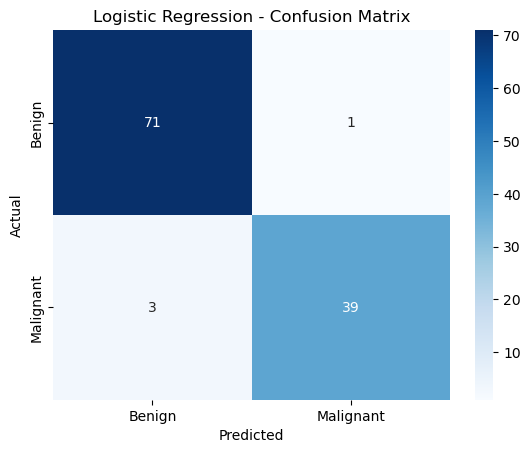

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [15]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    logistic_model,
    "models/logistic_regression.pkl"
)

['models/logistic_regression.pkl']

In [16]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

In [17]:
decision_tree_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=None,
    random_state=42
)

In [18]:
decision_tree_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [19]:
y_pred_dt = decision_tree_model.predict(X_test)

y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

In [20]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_auc = roc_auc_score(y_test, y_prob_dt)

dt_precision = precision_score(y_test, y_pred_dt)

dt_recall = recall_score(y_test, y_pred_dt)

dt_f1 = f1_score(y_test, y_pred_dt)

dt_mcc = matthews_corrcoef(y_test, y_pred_dt)

print("Decision Tree Results")
print("---------------------------")
print(f"Accuracy: {dt_accuracy:.4f}")
print(f"AUC Score: {dt_auc:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall: {dt_recall:.4f}")
print(f"F1 Score: {dt_f1:.4f}")
print(f"MCC: {dt_mcc:.4f}")

Decision Tree Results
---------------------------
Accuracy: 0.9298
AUC Score: 0.9246
Precision: 0.9048
Recall: 0.9048
F1 Score: 0.9048
MCC: 0.8492


In [21]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_dt,
    target_names=["Benign", "Malignant"]
))

Confusion Matrix:
[[68  4]
 [ 4 38]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.94      0.94      0.94        72
   Malignant       0.90      0.90      0.90        42

    accuracy                           0.93       114
   macro avg       0.92      0.92      0.92       114
weighted avg       0.93      0.93      0.93       114



In [22]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    decision_tree_model,
    "models/decision_tree.pkl"
)

print("Decision Tree model saved successfully!")

Decision Tree model saved successfully!


In [23]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [24]:
knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5,
        metric="minkowski",
        p=2
    ))
])

In [25]:
knn_model.fit(X_train, y_train)

print("KNN model trained successfully!")

KNN model trained successfully!


In [26]:
y_pred_knn = knn_model.predict(X_test)

y_prob_knn = knn_model.predict_proba(X_test)[:, 1]

In [27]:
knn_accuracy = accuracy_score(y_test, y_pred_knn)

knn_auc = roc_auc_score(y_test, y_prob_knn)

knn_precision = precision_score(y_test, y_pred_knn)

knn_recall = recall_score(y_test, y_pred_knn)

knn_f1 = f1_score(y_test, y_pred_knn)

knn_mcc = matthews_corrcoef(y_test, y_pred_knn)

print("KNN Results")
print("---------------------------")
print(f"Accuracy: {knn_accuracy:.4f}")
print(f"AUC Score: {knn_auc:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall: {knn_recall:.4f}")
print(f"F1 Score: {knn_f1:.4f}")
print(f"MCC: {knn_mcc:.4f}")

KNN Results
---------------------------
Accuracy: 0.9561
AUC Score: 0.9823
Precision: 0.9744
Recall: 0.9048
F1 Score: 0.9383
MCC: 0.9058


In [28]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=["Benign", "Malignant"]
))

Confusion Matrix:
[[71  1]
 [ 4 38]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97        72
   Malignant       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [29]:
import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    knn_model,
    "models/knn.pkl"
)

print("KNN model saved successfully!")

KNN model saved successfully!


In [30]:
from sklearn.naive_bayes import GaussianNB
naive_bayes_model = GaussianNB()
naive_bayes_model.fit(X_train, y_train)

print("Naive Bayes model trained successfully!")
y_pred_nb = naive_bayes_model.predict(X_test)

y_prob_nb = naive_bayes_model.predict_proba(X_test)[:, 1]

nb_accuracy = accuracy_score(y_test, y_pred_nb)

nb_auc = roc_auc_score(y_test, y_prob_nb)

nb_precision = precision_score(y_test, y_pred_nb)

nb_recall = recall_score(y_test, y_pred_nb)

nb_f1 = f1_score(y_test, y_pred_nb)

nb_mcc = matthews_corrcoef(y_test, y_pred_nb)

print("Naive Bayes Results")
print("---------------------------")
print(f"Accuracy: {nb_accuracy:.4f}")
print(f"AUC Score: {nb_auc:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall: {nb_recall:.4f}")
print(f"F1 Score: {nb_f1:.4f}")
print(f"MCC: {nb_mcc:.4f}")


print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_nb,
    target_names=["Benign", "Malignant"]
))


import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    naive_bayes_model,
    "models/naive_bayes.pkl"
)

print("Naive Bayes model saved successfully!")

Naive Bayes model trained successfully!
Naive Bayes Results
---------------------------
Accuracy: 0.9386
AUC Score: 0.9934
Precision: 1.0000
Recall: 0.8333
F1 Score: 0.9091
MCC: 0.8715
Confusion Matrix:
[[72  0]
 [ 7 35]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.91      1.00      0.95        72
   Malignant       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114

Naive Bayes model saved successfully!


In [31]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])


svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")


y_pred_svm = svm_model.predict(X_test)

y_prob_svm = svm_model.predict_proba(X_test)[:, 1]


svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_auc = roc_auc_score(y_test, y_prob_svm)

svm_precision = precision_score(y_test, y_pred_svm)

svm_recall = recall_score(y_test, y_pred_svm)

svm_f1 = f1_score(y_test, y_pred_svm)

svm_mcc = matthews_corrcoef(y_test, y_pred_svm)

print("SVM Results")
print("---------------------------")
print(f"Accuracy: {svm_accuracy:.4f}")
print(f"AUC Score: {svm_auc:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall: {svm_recall:.4f}")
print(f"F1 Score: {svm_f1:.4f}")
print(f"MCC: {svm_mcc:.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_svm,
    target_names=["Benign", "Malignant"]
))



import joblib
import os

os.makedirs("models", exist_ok=True)

joblib.dump(
    svm_model,
    "models/svm.pkl"
)

print("SVM model saved successfully!")

SVM model trained successfully!
SVM Results
---------------------------
Accuracy: 0.9737
AUC Score: 0.9947
Precision: 1.0000
Recall: 0.9286
F1 Score: 0.9630
MCC: 0.9442
Confusion Matrix:
[[72  0]
 [ 3 39]]

Classification Report:
              precision    recall  f1-score   support

      Benign       0.96      1.00      0.98        72
   Malignant       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114

SVM model saved successfully!
